# Baseline: OpenCV StereoSGBM

This notebook computes a disparity map with OpenCV's **Semi-Global Block Matching** (SGBM), used as a reference for the dynamic programming implementation in `stereo_dp.ipynb`.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Load the images

SGBM, like the DP method, needs a **rectified** pair: the images are aligned so that epipolar lines (where the matching point must lie) are horizontal, reducing the search to a single row.

Rectification requires the stereo calibration parameters ($K_L, K_R, R, T, D_L, D_R$). Most stereo datasets (Middlebury, KITTI…) already provide rectified images, which is the case here. See [Image rectification](https://en.wikipedia.org/wiki/Image_rectification) for details.

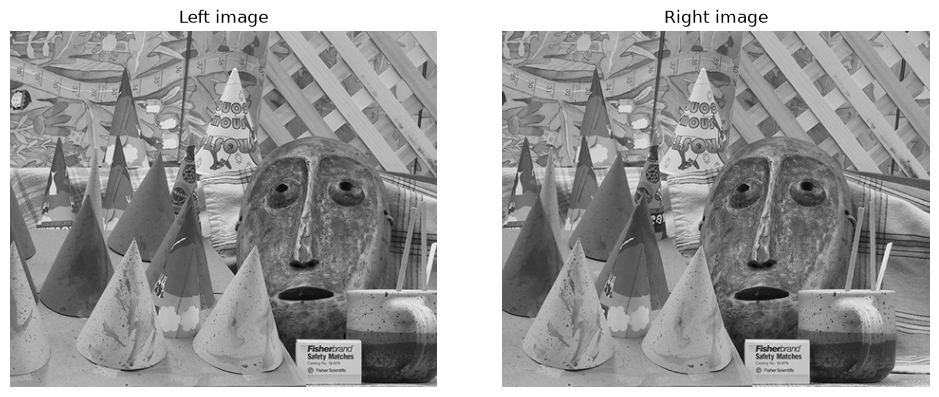

In [2]:
img_left_color = cv2.imread("../images/cones_left.png")
img_right_color = cv2.imread("../images/cones_right.png")

img_left = cv2.cvtColor(img_left_color, cv2.COLOR_BGR2GRAY)
img_right = cv2.cvtColor(img_right_color, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(img_left, cmap="gray"); ax[0].set_title("Left image"); ax[0].axis("off")
ax[1].imshow(img_right, cmap="gray"); ax[1].set_title("Right image"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 2. `cv2.StereoSGBM.create()`

**Disparity** is the horizontal offset of the same scene point between the two images; it is inversely proportional to depth.

SGBM improves on simple block matching by aggregating costs semi-globally: it penalises sudden disparity changes along several directions, giving a smoother and more consistent map.

Key parameters:

* `numDisparities` — maximum disparity searched (multiple of 16).
* `blockSize` — size of the window compared between the images.
* `P1` / `P2` — smoothness penalties for disparity changes of 1 and of more than 1.

In [3]:
numDisparities = 96  # must be a multiple of 16
blockSize = 5        # odd, typically 3-11

# P1: penalty for a disparity change of 1 between neighbouring pixels.
# P2: penalty for a change larger than 1 (P2 > P1).
cn = 1  # number of channels (1 for grayscale, 3 for colour)
P1 = 8 * cn * blockSize**2
P2 = 32 * cn * blockSize**2

stereo = cv2.StereoSGBM.create(
    minDisparity=0,
    numDisparities=numDisparities,
    blockSize=blockSize,
    P1=P1,
    P2=P2,
    uniquenessRatio=10,
    disp12MaxDiff=1,
)

# SGBM returns fixed-point disparities multiplied by 16
disparity = stereo.compute(img_left, img_right).astype(np.float32) / 16.0

## 3. Result

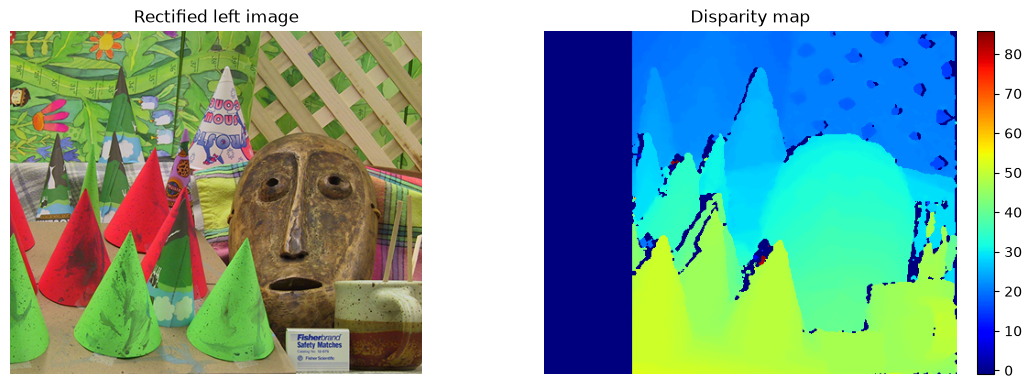

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cv2.cvtColor(img_left_color, cv2.COLOR_BGR2RGB)); ax[0].set_title("Rectified left image"); ax[0].axis("off")
im = ax[1].imshow(disparity, cmap="jet"); ax[1].set_title("Disparity map"); ax[1].axis("off")
fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

### Why is there a dark band on the left of the map?

It is a region that cannot be computed, not a bug. For each pixel of the left image, SGBM searches its match in the right image up to `numDisparities` pixels to the left. For pixels close to the left border, that search would go past the edge of the right image, so no valid match exists and the pixel is marked invalid (negative value), shown as the dark band. Its width equals `numDisparities`.

### Parameter reference

| Parameter | Meaning | Typical values | Effect |
| :--- | :--- | :--- | :--- |
| **`numDisparities`** | Number of disparity levels searched (depth range). | Multiple of 16 (64, 128, 256) | Larger → wider depth range, slower. |
| **`blockSize`** | Neighbourhood used for the matching cost (e.g. 5×5). | Odd (3, 5, 7) | Larger → smoother, less noise, loses fine detail. |
| **`P1 / P2`** | SGM smoothness penalties: $P_1$ for $\Delta d = 1$, $P_2$ for $\Delta d > 1$. | $P_2 > P_1$; usually $P_1 = 8 \cdot cn \cdot \text{blockSize}^2$, $P_2 = 32 \cdot cn \cdot \text{blockSize}^2$ | Controls smoothness. |
| **`disp12MaxDiff`** | Left-right consistency check: max difference between L→R and R→L disparities. | 1, 2; 0 disables | Filters wrong matches at occlusions. Smaller → more holes, more accurate. |
| **`uniquenessRatio`** | Margin (%) by which the best cost must beat the second best. | 5–15 | Larger → more holes, more reliable. |
| **`preFilterCap`** | Clipping value of the pre-filtered image. | 31 or 63 | Limits gradients, more robust in highly textured areas. |
| **`speckleWindowSize`** | Size of small disparity blobs treated as noise; 0 disables. | 100 | Removes small isolated wrong regions. |
| **`speckleRange`** | Max disparity variation inside a connected component. | 32 | Sensitivity of speckle removal. |
| **`mode`** | SGM variant. | `STEREO_SGBM_MODE_SGBM` (5 directions, default) | `MODE_HH` (8 directions) is better but uses more memory. |